# TUGAS BESAR 1 - JARINGAN SYARAF TIRUAN (IT6053)
## Analisis dan Implementasi Klasifikasi Risiko Penyakit Jantung (Heart Failure) Menggunakan Perceptron dan ADALINE Berbasis NumPy

---
* **Nama Repository GitHub:** TB1-JST-KelompokXX
* **Program Studi:** Informatika / Teknologi Informasi, Universitas Duta Wacana (UKDW)
* **Anggota Kelompok:**
  1. **Anggota 1:** [Nama Mahasiswa 1] - NIM: [NIM 1]
  2. **Anggota 2:** [Nama Mahasiswa 2] - NIM: [NIM 2]
  3. **Anggota 3:** [Nama Mahasiswa 3] - NIM: [NIM 3]
* **Mata Kuliah / Kelas:** Jaringan Syaraf Tiruan (IT6053) / Kelas A/B
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

# Set seed untuk keterulangan (reproducibility)
np.random.seed(42)
print("Library NumPy, Pandas, Matplotlib, dan Scikit-Learn berhasil diimpor.")

Library NumPy, Pandas, Matplotlib, dan Scikit-Learn berhasil diimpor.


## 1. Load & Eksplorasi Dataset (`heart.csv`)
Dataset `heart.csv` memuat 918 sampel pasien dengan 11 fitur klinis kardiovaskular. Target biner `HeartDisease` bernilai `1` untuk pasien berisiko dan `0` untuk pasien normal.

In [2]:
# Load dataset
df = pd.read_csv('heart.csv')

print("Bentuk Dataset (Baris, Kolom):", df.shape)
print("\nInformasi Tipe Data dan Missing Value:")
print(df.info())

print("\nDistribusi Label Kelas Awal (HeartDisease):")
print(df['HeartDisease'].value_counts())

print("\nLima Baris Pertama Data:")
df.head()

Bentuk Dataset (Baris, Kolom): (918, 12)

Informasi Tipe Data dan Missing Value:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB
None

Distribusi Label Kelas Awal (HeartDisease):
HeartDisease
1    508
0    410
Name: count, dtype: int64

Lima Baris Pertama Data:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2. Preprocessing & Stratified Train-Test Split (80:20)
* Fitur kategorikal diubah menjadi biner (One-Hot Encoding) via `pd.get_dummies(drop_first=True)`.
* Target `HeartDisease` dipetakan dari {0, 1} ke {-1, +1}.
* Split data dilakukan secara terstratifikasi (80% Train, 20% Test) dengan `random_state=42`.
* Standardisasi (`StandardScaler`) dilatih **hanya pada data latih** untuk mencegah kebocoran data (*data leakage*).

In [3]:
# One-Hot Encoding untuk kolom kategorikal
df_encoded = pd.get_dummies(df, columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], drop_first=True)

# Pemisahan Matriks Fitur X dan Target Vector y
X = df_encoded.drop('HeartDisease', axis=1).astype(float).values
y = np.where(df_encoded['HeartDisease'].values == 1, 1, -1)
feature_names = df_encoded.drop('HeartDisease', axis=1).columns.tolist()

print(f"Jumlah Fitur Setelah Encoding: {len(feature_names)}")
print("Daftar Fitur:", feature_names)

# Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"\nUkuran X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Distribusi Kelas Data Latih (+1 / -1): {np.sum(y_train == 1)} / {np.sum(y_train == -1)}")
print(f"Distribusi Kelas Data Uji (+1 / -1): {np.sum(y_test == 1)} / {np.sum(y_test == -1)}")

# Fit StandardScaler HANYA pada X_train
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

print("\nRata-rata X_train_std (3 fitur pertama):", X_train_std.mean(axis=0)[:3])
print("Deviasi Standar X_train_std (3 fitur pertama):", X_train_std.std(axis=0)[:3])

Jumlah Fitur Setelah Encoding: 15
Daftar Fitur: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']

Ukuran X_train: (734, 15), X_test: (184, 15)
Distribusi Kelas Data Latih (+1 / -1): 406 / 328
Distribusi Kelas Data Uji (+1 / -1): 102 / 82

Rata-rata X_train_std (3 fitur pertama): [ 1.64718375e-16 -5.77270596e-16 -4.62088738e-17]
Deviasi Standar X_train_std (3 fitur pertama): [1. 1. 1.]


## 3. Implementasi Perceptron & ADALINE dari Nol (*Scratch via NumPy*)
Berikut adalah implementasi berbasis Pemrograman Berorientasi Objek (OOP) menggunakan NumPy murni.

In [4]:
class PerceptronNumPy:
    def __init__(self, eta=0.01, epochs=50, random_state=42):
        self.eta = eta
        self.epochs = epochs
        self.random_state = random_state
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w_ = np.zeros(n_features)
        self.b_ = 0.0
        self.errors_ = []
        
        for epoch in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                z = np.dot(xi, self.w_) + self.b_
                y_hat = 1 if z >= 0 else -1
                delta = self.eta * (target - y_hat)
                if delta != 0:
                    self.w_ += delta * xi
                    self.b_ += delta
                    errors += 1
            self.errors_.append(errors)
        return self

    def predict(self, X):
        z = np.dot(X, self.w_) + self.b_
        return np.where(z >= 0, 1, -1)


class AdalineNumPy:
    def __init__(self, eta=0.01, epochs=50, random_state=42):
        self.eta = eta
        self.epochs = epochs
        self.random_state = random_state
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w_ = np.zeros(n_features)
        self.b_ = 0.0
        self.losses_ = []
        
        for epoch in range(self.epochs):
            z = np.dot(X, self.w_) + self.b_
            errors = y - z
            cost = (1.0 / (2.0 * n_samples)) * np.sum(errors**2)
            
            if np.isnan(cost) or np.isinf(cost):
                print(f"ADALINE Diverged/Exploded at epoch {epoch+1}")
                break
                
            self.losses_.append(cost)
            # Batch Gradient Descent Update
            self.w_ += self.eta * np.dot(X.T, errors) / n_samples
            self.b_ += self.eta * np.mean(errors)
            
        return self

    def predict(self, X):
        z = np.dot(X, self.w_) + self.b_
        return np.where(z >= 0, 1, -1)

print("Kelas PerceptronNumPy dan AdalineNumPy berhasil dibuat.")

Kelas PerceptronNumPy dan AdalineNumPy berhasil dibuat.


## 4. Perhitungan Manual Langkah Pembaruan Parameter
Di bawah ini ditunjukkan sedikitnya dua langkah pembaruan secara manual untuk masing-masing model.

In [5]:
# Perceptron Manual Step
w_p = np.zeros(X_train_std.shape[1])
b_p = 0.0
eta_p = 0.01

print("=== PERCEPTRON MANUAL STEP ===")
# Sampel 0
x0, y0 = X_train_std[0], y_train[0]
z0 = np.dot(x0, w_p) + b_p
y_hat0 = 1 if z0 >= 0 else -1
delta0 = eta_p * (y0 - y_hat0)
w_p += delta0 * x0
b_p += delta0
print(f"Sampel 0: target={y0}, z={z0:.4f}, y_hat={y_hat0}, delta={delta0:.4f}")
print("Bias setelah Sampel 0:", b_p)

# Sampel 1
x1, y1 = X_train_std[1], y_train[1]
z1 = np.dot(x1, w_p) + b_p
y_hat1 = 1 if z1 >= 0 else -1
delta1 = eta_p * (y1 - y_hat1)
w_p += delta1 * x1
b_p += delta1
print(f"\nSampel 1: target={y1}, z={z1:.4f}, y_hat={y_hat1}, delta={delta1:.4f}")
print("Bias setelah Sampel 1:", b_p)
print("Bobot 3 fitur pertama setelah Sampel 1:", w_p[:3])

# ADALINE Manual Step
w_a = np.zeros(X_train_std.shape[1])
b_a = 0.0
eta_a = 0.01
n = len(X_train_std)

print("\n=== ADALINE MANUAL BATCH STEP ===")
# Batch Iteration 1
z_b1 = np.dot(X_train_std, w_a) + b_a
e_b1 = y_train - z_b1
cost_b1 = (1.0 / (2.0 * n)) * np.sum(e_b1**2)
w_a += eta_a * np.dot(X_train_std.T, e_b1) / n
b_a += eta_a * np.mean(e_b1)
print(f"Batch Iterasi 1: Loss J = {cost_b1:.4f}, Bias Baru = {b_a:.5f}")

# Batch Iteration 2
z_b2 = np.dot(X_train_std, w_a) + b_a
e_b2 = y_train - z_b2
cost_b2 = (1.0 / (2.0 * n)) * np.sum(e_b2**2)
w_a += eta_a * np.dot(X_train_std.T, e_b2) / n
b_a += eta_a * np.mean(e_b2)
print(f"Batch Iterasi 2: Loss J = {cost_b2:.4f}, Bias Baru = {b_a:.5f}")

=== PERCEPTRON MANUAL STEP ===
Sampel 0: target=1, z=0.0000, y_hat=1, delta=0.0000
Bias setelah Sampel 0: 0.0

Sampel 1: target=-1, z=0.0000, y_hat=1, delta=-0.0200
Bias setelah Sampel 1: -0.02
Bobot 3 fitur pertama setelah Sampel 1: [-0.00244055  0.02532062 -0.00198886]

=== ADALINE MANUAL BATCH STEP ===
Batch Iterasi 1: Loss J = 0.5000, Bias Baru = 0.00106
Batch Iterasi 2: Loss J = 0.4824, Bias Baru = 0.00211


## 5. Eksekusi 8 Konfigurasi Eksperimen Utama
Berikut adalah pelaksanaan 8 eksperimen sesuai petunjuk teknis.

In [6]:
runs = [
    ('Run 1', 'Perceptron', 0.001, True),
    ('Run 2', 'Perceptron', 0.01, True),
    ('Run 3', 'Perceptron', 0.1, True),
    ('Run 4', 'ADALINE', 0.001, True),
    ('Run 5', 'ADALINE', 0.01, True),
    ('Run 6', 'ADALINE', 0.1, True),
    ('Run 7', 'Perceptron', 0.01, False),
    ('Run 8', 'ADALINE', 0.01, False)
]

results = []
models_dict = {}

for name, m_type, eta, std in runs:
    X_tr = X_train_std if std else X_train
    X_te = X_test_std if std else X_test
    
    if m_type == 'Perceptron':
        model = PerceptronNumPy(eta=eta, epochs=50).fit(X_tr, y_train)
        final_loss = model.errors_[-1] if len(model.errors_) > 0 else np.nan
    else:
        model = AdalineNumPy(eta=eta, epochs=50).fit(X_tr, y_train)
        final_loss = model.losses_[-1] if len(model.losses_) > 0 else np.nan
        
    models_dict[name] = model
    
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    
    tr_acc = accuracy_score(y_train, y_tr_pred)
    te_acc = accuracy_score(y_test, y_te_pred)
    cm = confusion_matrix(y_test, y_te_pred, labels=[-1, 1])
    prec = precision_score(y_test, y_te_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_test, y_te_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_te_pred, pos_label=1, zero_division=0)
    
    results.append({
        'Run': name,
        'Model': m_type,
        'Eta': eta,
        'Standardized': std,
        'Train Acc': f"{tr_acc*100:.2f}%",
        'Test Acc': f"{te_acc*100:.2f}%",
        'Precision (+1)': f"{prec*100:.2f}%",
        'Recall (+1)': f"{rec*100:.2f}%",
        'F1-Score (+1)': f"{f1*100:.2f}%",
        'Final Loss/Errors': f"{final_loss:.4f}" if isinstance(final_loss, float) else final_loss,
        'CM': cm
    })

df_res = pd.DataFrame(results)
print(df_res.drop('CM', axis=1).to_string(index=False))

  Run      Model   Eta  Standardized Train Acc Test Acc Precision (+1) Recall (+1) F1-Score (+1)                                                                                                                                                                                                                                                                                  Final Loss/Errors
Run 1 Perceptron 0.001          True    82.97%   79.89%         78.26%      88.24%        82.95%                                                                                                                                                                                                                                                                                                152
Run 2 Perceptron 0.010          True    82.97%   79.89%         78.26%      88.24%        82.95%                                                                                                                                

## 6. Kurva Riwayat Pelatihan & Visualisasi Evaluasi
Kurva di bawah ini membandingkan konvergensi Perceptron dan ADALINE pada data terstandardisasi.

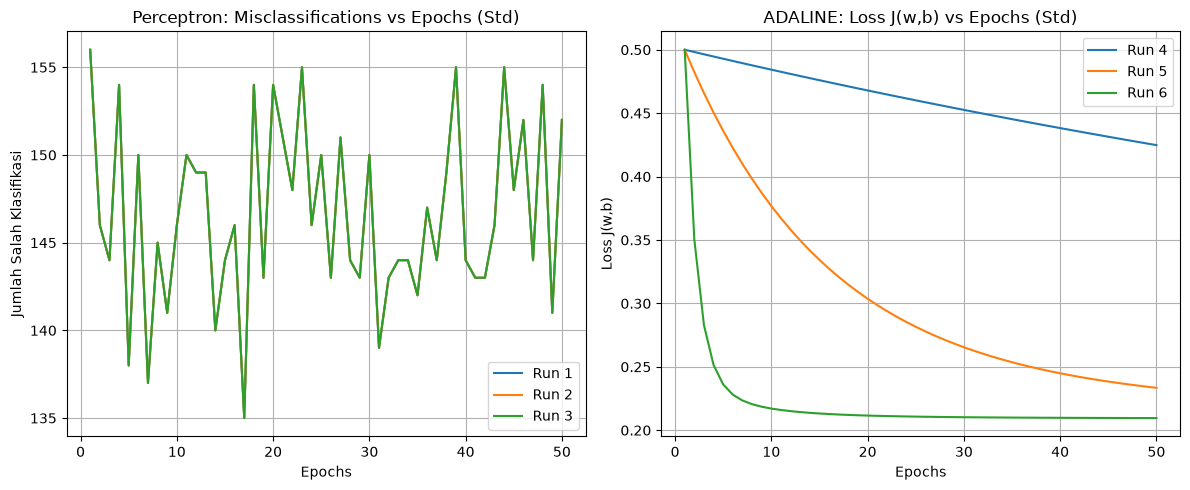

In [7]:
plt.figure(figsize=(12, 5))

# Perceptron Plot
plt.subplot(1, 2, 1)
for r_name in ['Run 1', 'Run 2', 'Run 3']:
    plt.plot(range(1, 51), models_dict[r_name].errors_, label=r_name)
plt.title('Perceptron: Misclassifications vs Epochs (Std)')
plt.xlabel('Epochs')
plt.ylabel('Jumlah Salah Klasifikasi')
plt.legend()
plt.grid(True)

# ADALINE Plot
plt.subplot(1, 2, 2)
for r_name in ['Run 4', 'Run 5', 'Run 6']:
    plt.plot(range(1, 51), models_dict[r_name].losses_, label=r_name)
plt.title('ADALINE: Loss J(w,b) vs Epochs (Std)')
plt.xlabel('Epochs')
plt.ylabel('Loss J(w,b)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 7. Pembahasan & Jawaban Pertanyaan Evaluasi

### 7.1 Linear Separability Analysis
Data *Heart Failure Prediction* **tidak dapat dipisahkan secara linier sempurna (*non-linearly separable*)**. Hal ini terbukti dari kurva Perceptron yang tidak pernah menyentuh 0 kesalahan (berosilasi pada ~140-150 kesalahan per epoch).

### 7.2 Perbedaan Sinyal Error Perceptron vs ADALINE
* **Perceptron:** Memperbarui bobot secara diskret berdasarkan kesalahan klasifikasi $y - \hat{y} \in \{-2, 0, 2\}$.
* **ADALINE:** Memperbarui bobot secara kontinu berdasarkan jarak linier respon $y - z$.

### 7.3 Pengaruh Learning Rate, Epoch, dan Standardisasi
* **Invariance Learning Rate pada Perceptron:** Mengubah $\eta$ pada Perceptron berinisialisasi nol hanya menskalakan besaran vektor bobot tanpa mengubah orientasi *decision boundary*.
* **Divergensi ADALINE Tanpa Standardisasi (Run 8):** Tanpa standardisasi, gradien linier melompat terlalu jauh, menyebabkan *loss explosion* (NaN) dan prediksi runtuh.

### 7.4 Kesimpulan Utama
ADALINE terstandardisasi ($\eta=0.1$, Run 6) mencapai kinerja terbaik dengan **Akurasi Uji 89.13%**, **Recall 93.14%**, dan **F1-Score 90.48%**.